---
title: Multiple testing
format:
    # typst:
    #     echo: false

    revealjs:
        smaller: true
        code-line-numbers: false
        echo: false
        include-in-header:
            - text: |
                <style>
                .reveal h1, .reveal h2, .reveal h3, .reveal h4 { text-align: center; }
                </style>
            - text: |
                <style>
                .center { text-align: center; display: block; }
                </style>
            - text: |
                <style>
                .orange { color: orange; display: block; }
                </style>
            - text: |
                <style>
                .white { color: white; display: block; }
                </style>
            - text: |
                <style>
                .reveal pre.sourceCode { font-size: 20px; }
                </style>

execute:
  enabled: false
editor:
    render-on-save: true
progress: true
incremental: true
slide-level: 3
jupyter: python3
display_name: "Python 3.11.5"
---

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from numpy.random import normal
from scipy.stats import ttest_ind
from statsmodels.formula.api import ols
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests

mpl.rc_file('/home/njs/miniconda3/lib/python3.11/site-packages/matplotlib/mpl-data/matplotlibrc')

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme('talk', style='white', rc=custom_params)

### The problem with multiple testing: An example

:::: {.columns}
::: {.column width="50%"}

<br>
<br>
<br>

Hawthorn can modestly lower blood pressure in people with mild hypertension

<br>
<br>
<br>

:::{.fragment fragment-index=1}
![](Images/homeopathy.png){width=300 }
:::
:::

::: {.column width="50%"}
![](Images/hawthorn.png){width=300}

:::{.fragment fragment-index=1}
As a homeopathic medicine, which contains no active ingredients, it has no effect on blood pressure
:::
:::
::::

In [122]:
#| output: false

def plot_hist(ps, filename):
    ax = sns.histplot(ps, bins=np.arange(0, 1.05, 0.05))
    ax.axvline(0.05, color='C1')
    ylim = ax.get_ylim()[1]
    ax.text(0.06, ylim, 'P = 0.05', fontsize=16, color='C1')
    ax.set_xlabel('P value')
    ax.set_xlim(-0.05, 1.05)
    plt.savefig(f'Images/{filename}.png', bbox_inches='tight')

In [126]:
#| output: false

before = normal(145, 2, size=10)
after = normal(145, 2, size=10)
diff = after - before

print('Before | After | Difference')
print('--: | --: | --:')
for b, a, d in zip(before, after, diff):
    print(f'{b:.0f} | {a:.0f} | {d:.0f} ')

Before | After | Difference
--: | --: | --:
146 | 146 | 0 
145 | 143 | -2 
143 | 142 | -1 
145 | 143 | -3 
146 | 145 | -1 
145 | 148 | 3 
142 | 147 | 5 
147 | 148 | 1 
148 | 143 | -5 
149 | 143 | -6 


0.3475186134371624


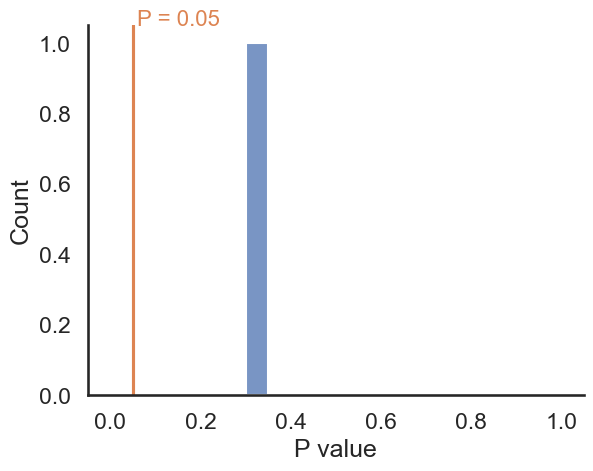

In [127]:
#| output: false

p1 = ttest_ind(before, after).pvalue
print(p1)
plot_hist([p1], 'one_p')


### The problem with multiple testing

:::: {.columns}
::: {.column width="40%"}

Before | After | Difference
--: | --: | --:
146 | 146 | 0 
145 | 143 | -2 
143 | 142 | -1 
145 | 143 | -3 
146 | 145 | -1 
145 | 148 | 3 
142 | 147 | 5 
147 | 148 | 1 
148 | 143 | -5 
149 | 143 | -6  

:::

::: {.column width="60%"}

An experiment in ten people with high blood pressure

- Measure systolic blood pressure (in mm Hg) before and after taking homeopathic hawthorn
- How compatible are the data with the null hypothesis of no change in blood pressure?
- *P* = 0.35, compatible, no significant effect

::: {.fragment}
![](Images/one_p.png){width=350}
:::

:::
::::

Before | After | Difference
--: | --: | --:
147 | 142 | -5 
147 | 146 | -0 
145 | 145 | 0 
146 | 143 | -4 
144 | 145 | 1 
145 | 144 | -1 
146 | 142 | -3 
144 | 144 | 0 
147 | 145 | -2 
146 | 146 | 0 
0.03531265097485477


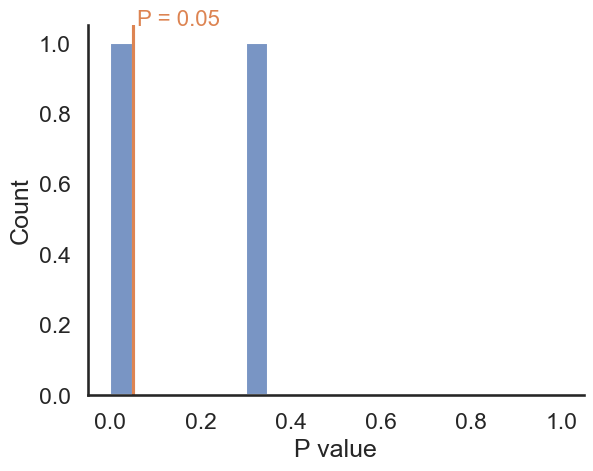

In [128]:
#| output: false

while True:
    before = normal(145, 2, size=10)
    after = normal(145, 2, size=10)
    if ttest_ind(before, after).pvalue < 0.05:
        break

diff = after - before

print('Before | After | Difference')
print('--: | --: | --:')
for b, a, d in zip(before, after, diff):
    print(f'{b:.0f} | {a:.0f} | {d:.0f} ')
p2 = ttest_ind(before, after).pvalue
print(p2)

plot_hist([p1, p2], 'two_p')


### The problem with multiple testing

:::: {.columns}
::: {.column width="40%"}

Before | After | Difference
--: | --: | --:
144 | 144 | 0 
143 | 146 | 3 
144 | 146 | 2 
145 | 145 | -1 
146 | 147 | 1 
146 | 147 | 1 
143 | 145 | 2 
144 | 148 | 4 
145 | 148 | 3 
145 | 143 | -2 
:::

::: {.column width="60%"}

A second experiment in a different lab

- *P* = 0.031, incompatible, a significant effect

::: {.fragment}
![](Images/two_p.png){width=500}
:::

:::
::::


In [119]:
#| output: false

while True:
    ps = []
    for i in range(100):
        before = normal(145, 2, size=10)
        after = normal(145, 2, size=10)
        ps.append(ttest_ind(before, after).pvalue)
    psa = np.array(ps)
    fp = len(psa[psa < 0.05])
    if fp == 5:
        break

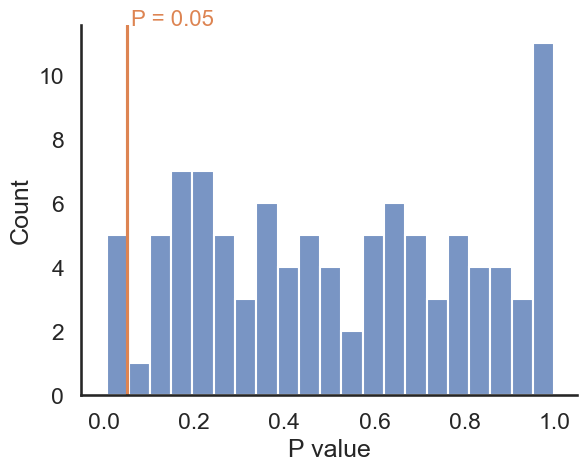

In [ ]:
#| output: false
plot_hist(ps, '100_p')


### The problem with multiple testing

:::: {.columns}
::: {.column width="50%"}

Consider 100 independent experiments

- In 100 independent experiments in which the null hypothesis is true, five are significant

- These are called false positives

- When the null hypothesis is true, 1 in 20 (5%) significance tests result in a false positive

- If your analysis requires multiple testing, you need to reduce your risk of making false claims

:::
::: {.column width="50%"}


![](Images/100_p.png){width=500}

:::
::::

### Multiple testing

Occurs in any scientific study where many statistical hypotheses are tested simultaneously on the same dataset

- Multiple treatments: 

    - Comparing plant biomass with different fertilisers compared to a control of no fertiliser
    - Bird species richness is compared between old-growth forest, logged forest, pine plantation and urban park (6 pairwise comparisons)
    - Multiple drugs screened simultaneously for liver toxicity

- Multiple outcomes: 

    - A drug trial evaluating a new medication might track its impact on many different health endpoints (e.g., blood pressure, cholesterol, heart rate, kidney function, and stroke risk)
    - Differential expression of thousands of genes/proteins between a control and treatment 

### Two main methods to control for multiple testing

- The Holm method (published by Sture Holm in 1979)
    - Use when false positives are costly
        - Clinical trials, safety decisions, regulatory settings
        - A small number of pre-specified comparisons

- ~~Bonferroni method~~
    - No longer recommended as too conservative (rejects too many true positives). Use Holm instead

### Two main methods to control for multiple testing

- The Benjamini–Hochberg method (published in 1995)
    - Use when you're screening and can tolerate some false leads
        - Genomics, proteomics, neuroimaging (hundreds–thousands of tests)
        - Exploratory/discovery phase where follow-up validation will catch false positives


### Holm: Comparing treatments to a control

:::: {.columns}
::: {.column width="50%"}

- Plants were grown with
    - no fertiliser (control)
    - fertiliser A (treatment 1)
    - fertiliser B (treatment 2)

- Their dry mass (in grams) was measured after 8 weeks.

:::
::: {.column width="50%"}

![](Images/plant_growth.jpg){width=500}

:::
::::



### Read in and print the data {.scrollable}

In [142]:
#| echo: true

pg = pd.read_csv('../Datasets/plant_growth.csv')
pg


,weight,group
0,4.17,ctrl
1,5.58,ctrl
2,5.18,ctrl
3,6.11,ctrl
4,4.50,ctrl
5,4.61,ctrl
6,5.17,ctrl
7,4.53,ctrl
8,5.33,ctrl
9,5.14,ctrl


### Plot the dry mass for each group

In [ ]:
sns.boxplot(data=pg, x='group', y='weight', fill=None)
sns.swarmplot(data=pg, x='group', y='weight', size=10);
plt.savefig('Images/plant_growth_data.png', bbox_inches='tight')

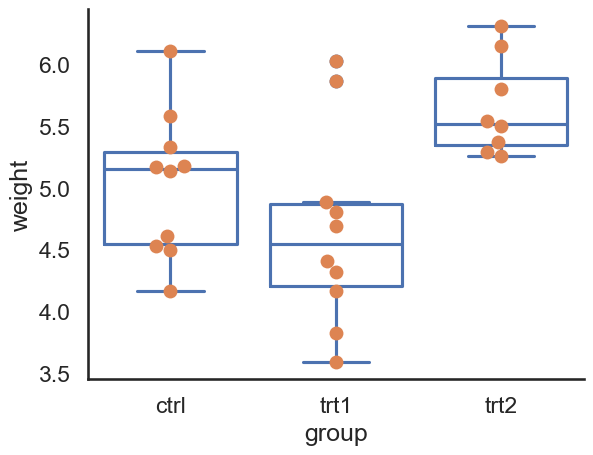

In [143]:
#| echo: true
#| fig-align: center
sns.boxplot(data=pg, x='group', y='weight', fill=None)
sns.swarmplot(data=pg, x='group', y='weight', size=10);

### Step 1: Do an ANOVA "omnibus" test


:::: {.columns}
::: {.column width="50%"}

Check the compatibility of the data with the null hypothesis that all means are the same.

- If the data are compatible with the null (*P* > 0.05) the analysis stops there.
- If the data are incompatible with the null (*P* < 0.05) the analysis moves onto pairwise comparison with *t*-tests.
:::
::: {.column width="50%"}
![](Images/plant_growth_data.png){width=500}
:::
::::


### Two ways to code an ANOVA in python

::: {.fragment}
#### anova_oneway

In [ ]:
#| echo: true
#| output-location: fragment

from statsmodels.stats.oneway import anova_oneway

test = anova_oneway(pg['weight'], pg['group'], use_var='equal')

print(test.df)
print(test.statistic)
print(test.pvalue)

(2.0, 25.0)
5.594501009822159
0.009818440749277929


:::

### Two ways to code an ANOVA in python

::: {.fragment}

#### Linear model

In [ ]:
#| echo: true
#| output-location: fragment

formula = 'weight ~ group'
fit = ols(formula, pg).fit()
fit.summary().tables[0]

Dep. Variable:,weight,R-squared:,0.309
Model:,OLS,Adj. R-squared:,0.254
Method:,Least Squares,F-statistic:,5.595
Date:,"Thu, 29 Oct 2026",Prob (F-statistic):,0.00982
Time:,13:58:49,Log-Likelihood:,-25.078
No. Observations:,28,AIC:,56.16
Df Residuals:,25,BIC:,60.15
Df Model:,2,,
Covariance Type:,nonrobust,,


:::

### Step 1: Do an ANOVA "omnibus" test

:::: {.columns}
::: {.column width="50%"}

Both give the same result

- *F*~2,25~ = 5.59
- *P* = 0.0098

- Conclusion: At least one mean is different from at least one of the others.
- But are the treatments different to the control?
:::

::: {.column width="50%"}
![](Images/plant_growth_data.png){width=500}
:::
::::


### Step 2: Compare the treatments to the control

We need the raw *P*-values of the significance tests which we can obtain from the linear model

In [96]:
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,5.0320,0.198,25.374,0.000,4.624,5.440
group[T.trt1],-0.3710,0.280,-1.323,0.198,-0.949,0.207
group[T.trt2],0.6205,0.297,2.086,0.047,0.008,1.233


- Treatment 1 vs. control: *P*~raw~ = 0.198
- Treatment 2 vs. control: *P*~raw~ = 0.047

### Step 3: Adjust the raw *P*-values for multiple testing

In [ ]:
#| echo: true
#| output-location: fragment

from statsmodels.stats.multitest import multipletests

# extract the raw p-values from the linear model
p_raw = fit.pvalues.iloc[1:]

# apply adjustment using the Holm method
p_adj = multipletests(p_raw, method="holm")[1]
p_adj

array([0.1978613, 0.0946938])

- Treatment 1 vs. control: *P*~adj~ = 0.198, not significant
- Treatment 2 vs. control: *P*~adj~ = 0.095, not significant

::: {.fragment}
Conclusion: **No evidence either fertiliser changed plant biomass**
:::
::: {.fragment}
By correcting for multiple testing we reduced the risk of making false claims.
:::

### Benjamini-Hochberg: differential gene expression

:::: {.columns}
::: {.column width="50%"}

![](Images/Asthma_airways.png){width=500}
:::
::: {.column width="50%"}
- Researchers wanted to better understand how the steroid, dexamethasone, suppresses inflammation in the lungs of people with asthma. 
- They did this by identifying which genes of airway smooth muscle cells were differentially expressed when treated with dexamethasone. 
- RNA-Seq, a high-throughput sequencing method, was used to quantify transcriptomic changes in thousands of genes.
:::
::::

### Load and print the data


:::: {.columns}
::: {.column width="60%"}


In [6]:
#| echo: true

rna = pd.read_csv('../Datasets/airway_merged_data_cleaned.csv')
rna.head(10)

,gene_id,dex,cell_line,count
0,E000003,treated,S09,448
1,E000003,treated,S13,408
2,E000003,treated,S17,1047
3,E000003,treated,S21,572
4,E000003,untreated,S08,679
5,E000003,untreated,S12,873
6,E000003,untreated,S16,1138
7,E000003,untreated,S20,770
8,E000419,treated,S09,515
9,E000419,treated,S13,365


:::
::: {.column width="40%"}

<br>
<br>

- There are 25,403 genes
- Four airway smooth muscle cell lines were treated with dexamethasone (S09, S13, S17, S21)
- Four airway smooth muscle cell lines were **not** treated with dexamethasone (S08, S12, S16, S20)
- The number of RNA short read sequences were counted in each cell line
:::
::::

### Plot the read counts for the first gene

We have to log-transform RNA read counts (explained why in the workflow notebook)

In [7]:
rna['log count'] = np.log2(rna['count'] + 1)


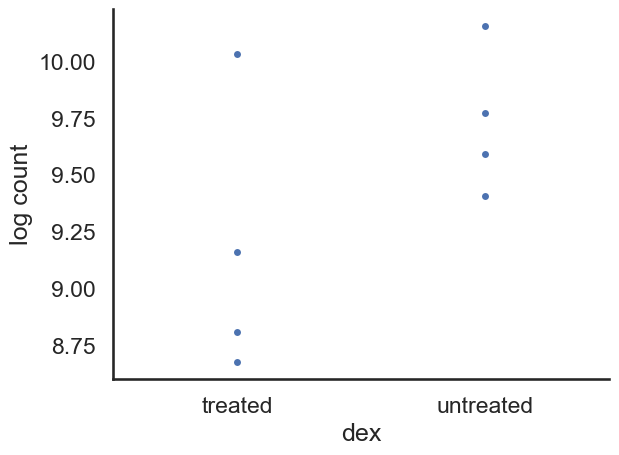

In [8]:
#| echo: true

sns.swarmplot(data=rna.query('gene_id == "E000003"'), y='log count', x='dex');

### Step 1: Perform a *t*-test on each gene

- Null hypothesis: mean read counts are the same for treated and untreated cell lines for each gene
- There are 25,403 genes
- That's 25,403 *t*-tests
- If the null hypothesis were true for all of them we would get

    $$25{,}403 \times 0.05 = 1{,}207\ \text{false positives}$$

- We need to filter out as many false positives as possible


### Step 1: Perform a *t*-test on each gene {.scrollable}

The code to do this is in the workflow notebook.

In [11]:
results_df = pd.read_csv('../Datasets/gene_results.csv')
results_df

,gene_id,p_raw
0,E000003,0.154514
1,E000419,0.925824
2,E000457,0.527302
3,E000460,0.443651
4,E000971,0.598771
...,...,...
25398,E273477,0.698030
25399,E273483,0.473038
25400,E273486,0.510124
25401,E273487,0.029086


### Step 1: Perform a *t*-test on each gene

#### Distribution of raw *P*-values for 25,403 genes

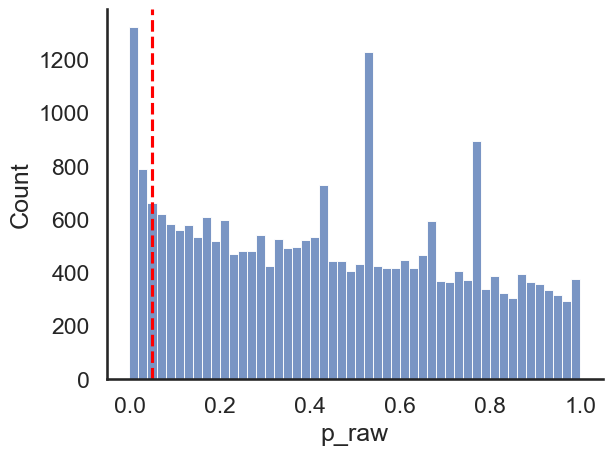

In [ ]:
#| fig-align: center

ax = sns.histplot(results_df['p_raw'], bins=50, edgecolor='white');
ax.axvline(0.05, color='red', linestyle='--');

There are 2,432 genes with *P* < 0.05

### Step 2: Adjust raw *P*-values using the Benjamini-Hochberg method {.scrollable}


In [5]:
#| echo: true
#| output-location: fragment

results_df['p_adj'] = multipletests(results_df['p_raw'], method='fdr_bh')[1]
results_df

,gene_id,p_raw,p_adj
0,E000003,0.154514,0.713029
1,E000419,0.925824,0.972746
2,E000457,0.527302,0.856147
3,E000460,0.443651,0.856147
4,E000971,0.598771,0.881235
...,...,...,...
25398,E273477,0.698030,0.907591
25399,E273483,0.473038,0.856147
25400,E273486,0.510124,0.856147
25401,E273487,0.029086,0.428529


### What Benjamini-Hochberg does to *P*-values

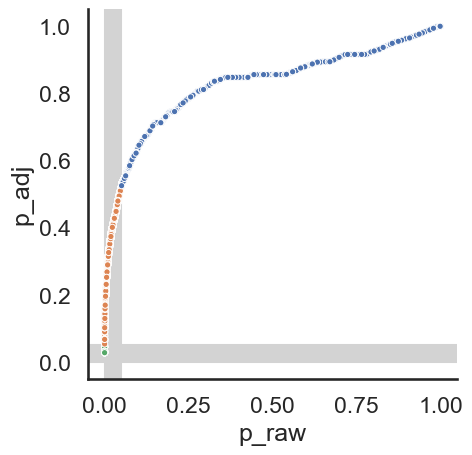

In [ ]:
#| fig-align: center

def label(row):
    """ return a string on whether p_raw and p_adj are greater or less than 0.05 """
    return f"p_raw {'<' if row['p_raw'] < 0.05 else '>'} 0.05 and p_adj {'<' if row['p_adj'] < 0.05 else '>'} 0.05"


results_df['significance'] = results_df.apply(lambda row: label(row), axis=1)

ax = sns.scatterplot(data=results_df, x='p_raw', y='p_adj', hue='significance', marker='.', legend=False)
ax.set_aspect('equal')
ax.axvspan(0, 0.05, ls='-', color='LightGrey', zorder=0)
ax.axhspan(0, 0.05, ls='-', color='LightGrey', zorder=0);

### Print out the genes with significant adjusted *P* values {.scrollable} 

:::: {.columns}
::: {.column width="50%"}


In [139]:
discoveries = results_df.query('p_adj < 0.05')[['gene_id', 'p_raw', 'p_adj']].sort_values('p_adj')
discoveries

,gene_id,p_raw,p_adj
291,E013297,0.000009,0.028547
13575,E187193,0.000015,0.028547
11471,E173110,0.000014,0.028547
8664,E155962,0.000006,0.028547
8347,E152583,0.000003,0.028547
7378,E143494,0.000007,0.028547
6027,E134253,0.000005,0.028547
5284,E128285,0.000012,0.028547
4729,E122877,0.000011,0.028547
24138,E267683,0.000012,0.028547


:::
::: {.column width="50%"}

There are 34 such genes

- The Benjamini-Hochberg method says that, of all the significant genes discovered, on average 5% of them are expected to be false positives. 

- There are 34 discovered genes. 5% of that is 1.7 genes. So we might expect of all the genes discovered, 1 or 2 of them are false positives.

- That is much better than using the raw *P*-values which gave us 2,432 genes with significantly changed expression. 
:::
::::

### Volcano plot of log-fold change in gene expression against significance

This is explained in more detail in the workflow notebook.

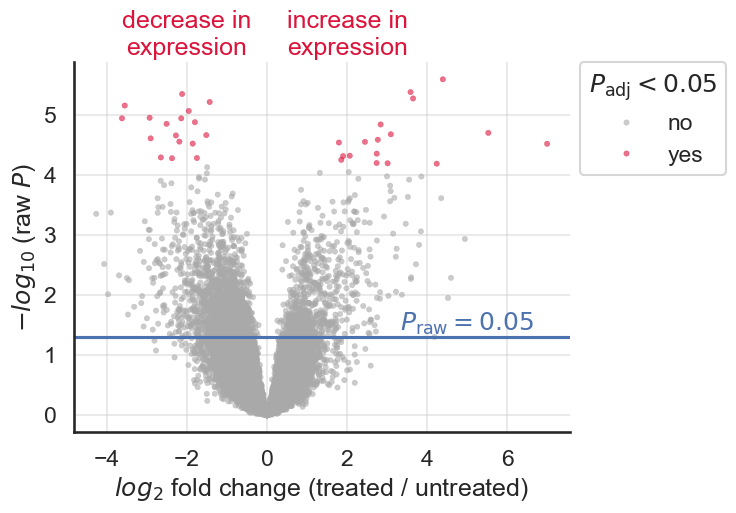

In [140]:
#| fig-align: center

results_df = pd.read_csv('../Datasets/gene_results2.csv')
ax = sns.scatterplot(
    data=results_df,
    x='log2fc',
    y='-log10_p_raw',
    hue='significant',
    palette={'yes': 'crimson', 'no': 'darkgray'},
    alpha=0.6,
    edgecolor=None,
    s=15
)

ax.set_xlabel('$log_2$ fold change (treated / untreated)')
ax.set_ylabel('$-log_{10}$ (raw $P$)')
ax.axhline(-np.log10(0.05))
ax.text(5, -np.log10(0.05), r'$P_\text{raw}=0.05$', ha='center', va='bottom', color='C0');
ax.text(2, 6, 'increase in\nexpression', ha='center', color='crimson')
ax.text(-2, 6, 'decrease in\nexpression', ha='center', color='crimson');
ax.grid(True, alpha=0.4)

ax.legend(title=r'$P_\text{adj} < 0.05$', loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0);


### Class 12 notebook

::: {.nonincremental}

Three questions on multiple testing:

1. Compare multiple treatments to a control (Holm)
2. Compare each treatment to every other treatment (Holm)
3. Multiple individual tests (Benjamini-Hochberg)

Workflow notebooks

1. **workflow_plant_growth.ipynb**: Multiple tests against a control
2. **workflow_iris_sepal_width.ipynb**: Pairwise tests between all treatments
3. **workflow_gene_expression.ipynb**: Multiple individual tests
:::